# 05-sleep实现与定时时间片轮转

> 硬件定时器提供时间基准，计时中断更新等待状态，调度器决定谁运行，上下文切换让选中的任务正确继续。等待到期、变为可运行和真正执行，是三个不同的时刻。

这是《自己动手写嵌入式操作系统》五篇笔记的第 05 篇，也是本系列最后一篇。接着第 04 篇的延时分析，本篇用配套源码串起任务等待、计数唤醒和定期调度。


## 1. 本篇范围与资料说明

| 视频 | 已核对的目录标题 | 本篇重点 |
|---|---|---|
| 18 | 采用硬件delay实现sleep函数 | 任务状态、等待参数、定时器0计数与唤醒 |
| 19 | 老师监管定期时间片轮转 | 定时器1中断入口、调度频率与上下文要求 |

**配套证据：**已核对视频目录，读取 `代码/os_demo.zip` 中的 `main.c`、`Listings/main.lst`、`Listings/project.m51`、`project.uvproj` 和 `Objects/project.hex`。目标为 STC8H8K64U Series；已有编译产物使用 C51 V9.60.7.0、SMALL 模型和 `RAMSIZE(256)`。

**补充参考：**核对了 [STC8H系列技术参考手册](https://stcmicro.com/datasheet/STC8H-cn.pdf) 第14章中的定时器模式、重装值和周期公式，以及定时器0/1范例。本篇引用的手册页码同时给出PDF页和印刷页，避免混淆。

视频未逐段观看或转录。源码及机器码是包内综合示例；流程图、计算例子、同步改进框架为补充说明。本篇没有重新编译、在模拟器执行或做硬件运行验证，不能把静态分析当成已验证的内核修复。


## 2. 等待与调度由哪些对象连接起来？

配套代码的职责可以概括为：

| 对象或函数 | 实际职责 |
|---|---|
| `tasks[]` | 保存任务状态、计数与等待长度 |
| `sleep(tid, delay_ms)` | 写入挂起状态与等待参数，然后返回 |
| `Timer0_ISR` | 累加挂起任务的计数，达到阈值时改回可运行状态 |
| 任务循环 | 检查自己的挂起状态，挂起时主动让出 |
| `task_switch` | 保存当前SP、任务编号轮转、恢复目标SP |
| `Timer1_ISR` | 源码中定义的定期切换入口；是否工作还取决于启用和切换协议 |

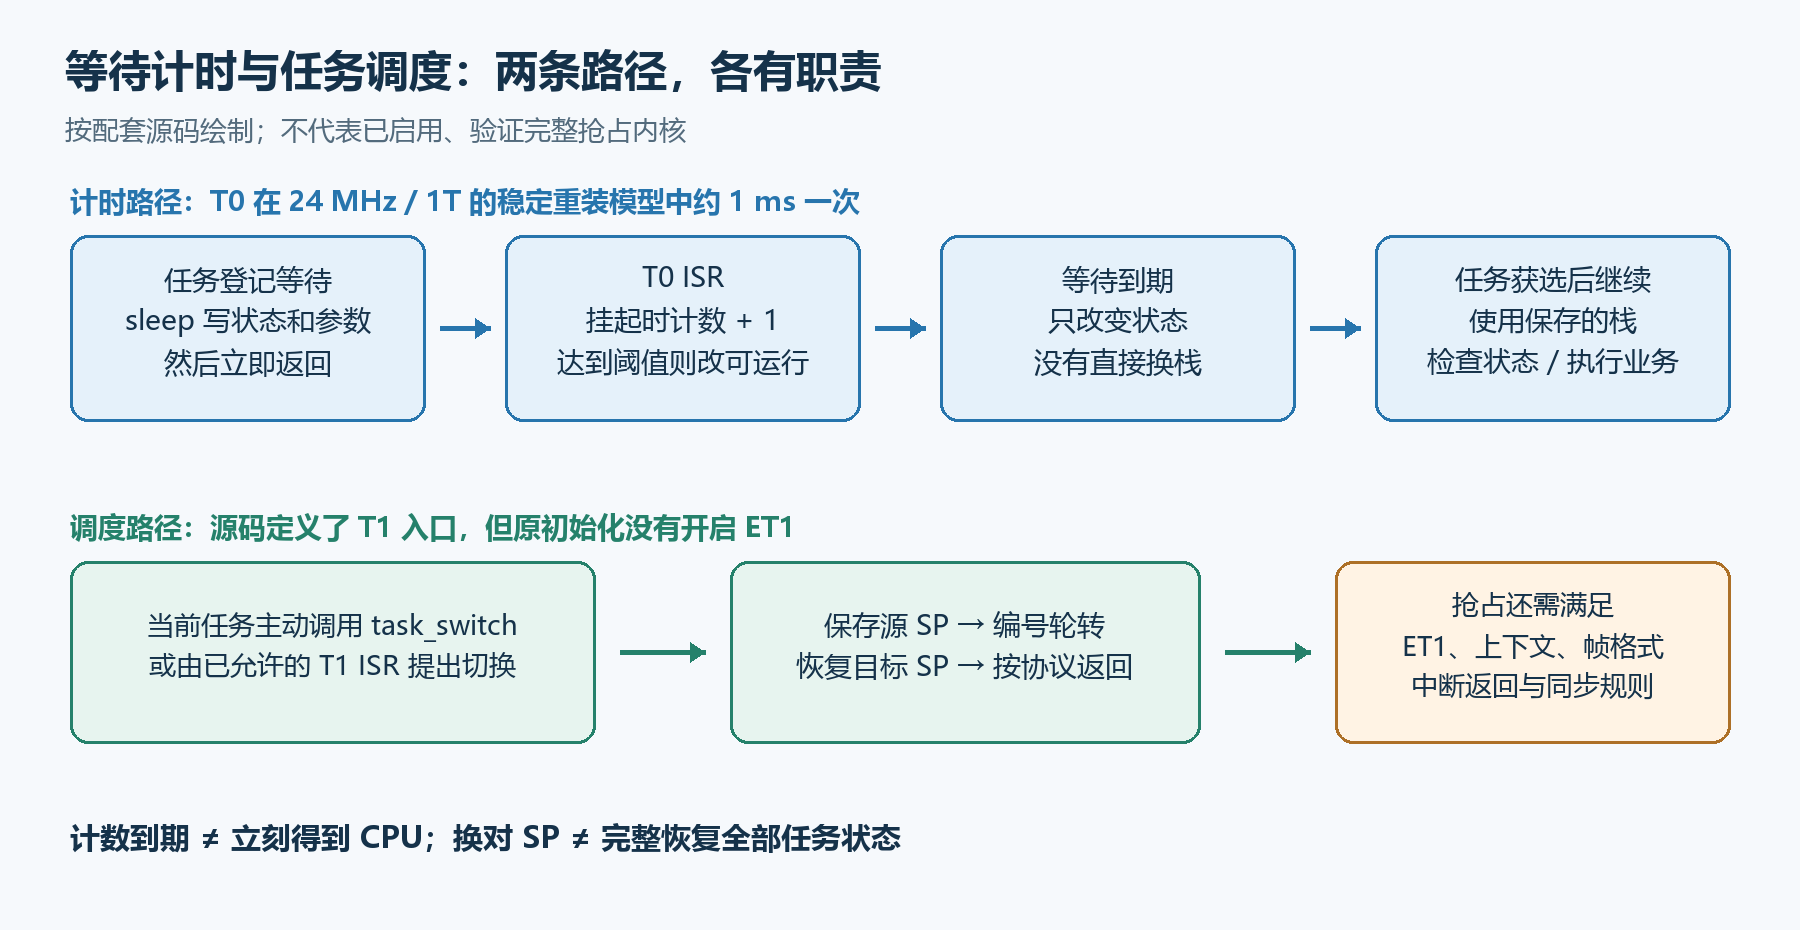

*自绘补充示意图。定时器1路径是源码意图，不表示当前包已启用并验证抢占。*

计时器可以持续工作，任务不用靠执行一秒减一循环来等待一秒。这解决的是时间来源；线程安全、就绪选择和上下文保护仍需要分别成立。


## 3. 源码怎样表示任务状态？

以下为 `main.c` 的**源码摘录**，去掉注释并统一空白：

```c
typedef enum{
    TASK_RUNNING,
    TASK_SUSPENDED
} TaskStatus;

typedef struct{
    unsigned char id;
    TaskStatus status;
    unsigned int delay_count;
    unsigned int delay_duration;
}Task;

Task idata tasks[MAX_TASKS] = {
    {0, TASK_RUNNING,0,0},
    {1, TASK_RUNNING,0,0},
};
```

| 字段 | 含义 | 阅读提醒 |
|---|---|---|
| `id` | 记录任务编号 | `task_switch` 实际使用的是全局 `task_id` |
| `status` | 是否允许任务继续业务 | 这里只分两个状态 |
| `delay_count` | 已服务的计时tick数 | 不天然等于毫秒 |
| `delay_duration` | 到期阈值 | 单位必须与tick对应 |

**补充校正：**这里两个任务可以同时标为 `TASK_RUNNING`，但单核同一时刻只执行一个任务。所以该枚举在本例更接近“允许继续/可运行”，没有严格区分就绪和正在执行。

同样，`TASK_SUSPENDED` 在这里被用作计时等待，不宜直接套成成熟RTOS中独立的“人工挂起”语义。本篇分析时保留源码名称，并按其实际行为解释。


## 4. sleep只是登记等待，并不在函数内阻塞

配套源码：

```c
void sleep(unsigned int task_id , unsigned int delay_ms){
    tasks[task_id].status = TASK_SUSPENDED;
    tasks[task_id].delay_count = 0;
    tasks[task_id].delay_duration = delay_ms;
}
```

该函数没有忙等待循环，没有读取硬件计数器，也没有调用 `task_switch`。它把等待记录写好后立即返回。

注意参数 `task_id` 与全局当前任务编号同名，但在本函数内是传入的任务编号。接口允许指定数组项，并没有自动限定为“调用者自己”，也没有检查编号是否小于 `MAX_TASKS`。

**补充理解：**函数名 `sleep` 不保证它具有桌面系统或某RTOS的标准阻塞契约。若要封装一个“当前任务睡眠、恢复后再返回”的接口，还需要明确登记、让出、恢复路径、零等待语义和同步规则。


## 5. 任务怎样在登记之后真正让出？

以下为任务0循环中的**源码摘录**：

```c
if(tasks[0].status == TASK_SUSPENDED){
    task_switch();
    continue;
}

sleep(0,1000);
P53 = ~P53;
task_switch();
```

实际顺序是：

```text
本轮状态允许业务
→ 登记1000个tick的等待
→ sleep返回，本轮仍翻转P5.3
→ 主动调用task_switch
→ 再次恢复后回到循环
→ 若仍挂起，就再次让出
```

任务1有相应的 `sleep(1,1000)`、P2.7翻转和让出。两项任务各有一份等待计数，定时器0会在同一次中断中检查两者。

**关键结论：**等待作用于之后的业务轮次；不是调用 `sleep` 后先停住1000ms，再执行紧接着的翻转。本轮在 `sleep` 和 `task_switch` 之间添加的其他语句，也可能立即执行。


## 6. Timer0 ISR怎样累加和唤醒？

下面是**完整函数的源码摘录**，仅删注释并整理格式：

```c
void Timer0_ISR(void) interrupt 1 {
    unsigned char i;
    for(i = 0; i < MAX_TASKS; i++){
        if(tasks[i].status == TASK_SUSPENDED){
            tasks[i].delay_count++;
        }
        if(tasks[i].delay_count >= tasks[i].delay_duration){
            tasks[i].status = TASK_RUNNING;
            tasks[i].delay_count = 0;
        }
    }
}
```

一次ISR对每个任务做：检查是否挂起、必要时加一、比较阈值、到期则改状态并清计数。

**源码边界要看清：**第二个 `if` 在第一个 `if` 外面。比较会对所有任务执行，不只对挂起任务执行。初始计数与阈值都是0，所以初始可运行任务会通过 `0>=0` 比较，重复写可运行状态和零计数。

这不等于“每次中断都把所有任务叫醒”：阈值为正、计数未到时比较仍为假。但不能把正文伪写成“只对挂起任务执行比较”，那会与源码不同。

该ISR没有调用 `task_switch`，所以它修改等待状态后通常返回原任务。唤醒和立刻切到该任务是不同动作。


## 7. 用3个tick追踪一次等待

以下为**简化补充推演**：假设等待登记是完整且同步的、tick连续服务，没有并发写入干扰。设 `delay_duration=3`：

| 时刻 | 比较前计数 | 比较结果 | 本次服务后状态/计数 |
|---|---|---|---|
| 登记完成 | 0 | 尚未比较 | 挂起，计数0 |
| tick1 | 1 | `1>=3`为假 | 挂起，计数1 |
| tick2 | 2 | `2>=3`为假 | 挂起，计数2 |
| tick3 | 3 | `3>=3`为真 | 可运行，计数被清为0 |

之后该任务被选中，才能继续业务。ISR把状态改回可运行时，没有重建任务入口，也没有重置函数局部进度；恢复位置仍由任务栈与上下文协议决定。

如果A、B在同一基准附近分别登记3和5个tick，两者的计数在各次ISR里都推进；不会因为CPU先给A执行，就必须先等A全部结束才开始给B计时。


## 8. 定时器0的实际初始化

配套源码的**实际顺序**为：

```c
void Timer0_init(){
    AUXR |= 0x80;
    TMOD &= 0xF0;
    EA = 1;
    ET0 = 1;
    TR0 = 1;
    TL0 = 0x40;
    TH0 = 0xA2;
}
```

| 操作 | 在本目标中的作用 |
|---|---|
| `AUXR |= 0x80` | 设置T0x12，定时器0按1T计数 |
| `TMOD &= 0xF0` | 清低半字节，保留定时器1配置；T0使用内部计时、模式0等设置 |
| `EA=1` | 全局允许普通中断 |
| `ET0=1` | 允许定时器0中断 |
| `TR0=1` | 启动定时器0计数 |
| `TL0/TH0`写入 | 对应组合值 `0xA240`，具体影响要结合运行状态 |

**手册核对：**STC8H的定时器0/1模式0是 **16位自动重装载**；不能照搬经典8051的模式0为13位计数的解释。模式与1T/12T选择是两件事。

手册依据：第14.3.2—14.3.3节，PDF第476—478页，印刷第454—456页。


## 9. 先启动再写TH/TL，会影响首次计时

STC8H手册说明，模式0有隐藏重装寄存器：

| 状态 | 写TH/TL的行为 |
|---|---|
| `TRn=0`，计数停止 | 写入当前计数寄存器，同时写对应隐藏重装寄存器 |
| `TRn=1`，计数运行 | 写入对应隐藏重装寄存器，不直接改当前计数值 |

定时器溢出后，把隐藏重装值重新装入计数器。依据为第14.3.3、第14.3.7节，PDF第478、480—481页，印刷第456、458—459页。

因此，源码 `TR0=1` 后才写 `TL0/TH0`，并不是“从写好的0xA240开始第一轮计数”的确定顺序。首次溢出可能从启动时已有计数值开始，稳定重装后的周期才对应新值；读TH/TL也不等于读取隐藏重装值。

**补充初始化原则：**在已停止计数的条件下完成模式、初值、状态准备，处理待决标志，再按约定允许中断和启动，可使首次计时更明确。实际顺序还要与任务初始栈及内核入口一起设计。

配套 `main` 在加载两项任务之前调用定时器初始化，且定时器0会先被允许进入。此时包内静态任务数组已有初值，但首次任务栈与调度入口仍需要纳入启动时序分析。不能只凭“代码能编译”就认定所有启动交错都已覆盖。


## 10. 为什么0xA240对应1ms？

以下是依据手册公式的**条件计算**：内部计时、模式0、重装值完整、1T、实际系统时钟为24MHz，并讨论稳定重装周期。

```text
16位计数空间：65536
重装值：0xA240 = 41536
一轮计数：65536 - 41536 = 24000
周期：24000 / 24000000 Hz = 0.001 s = 1 ms
```

| 模型 | 周期公式 |
|---|---|
| 1T | `(65536 - 重装值) / SYSclk` |
| 12T | `(65536 - 重装值) × 12 / SYSclk` |

这里1T说明定时器每个系统时钟计数一次，不表示ISR内每条CPU指令都只耗一个时钟。源码注释“每隔1毫秒执行ISR”还需要真实时钟、允许位、响应和服务情况支持。

若一毫秒服务一次且没有丢tick，`delay_duration=1000`表示1000个tick，才约等于一秒。若tick改成2ms，仍直接传1000就会约等两秒；需要明确毫秒到tick的转换和舍入规则。

公式依据：手册第14.3.14—14.3.15节，PDF第483—484页，印刷第461—462页。


## 11. 源码24MHz注释与工程35MHz描述

`Delay1000ms` 和 `Timer1_Init` 的源码注释使用24MHz；`project.uvproj` 中的 CPU 描述包含：

```text
CLOCK(35000000)
```

这是工程描述中的配置数值，**不证明板上实际运行35MHz**。该C文件也没有提供足以独立确认真实硬件频率的时钟设置与测量结果。

若只比较两个假设时钟、保持1T和重装值不变：

| 假设SYSclk | T0：`0xA240` | T1：`0xF6A0` |
|---|---|---|
| 24MHz | 1ms | 100μs |
| 35MHz | 约0.685714ms | 约68.5714μs |

例如实际为35MHz时，1000个稳定T0 tick约为0.685714秒，而不是1秒。这里是条件算例，不是硬件实测；真实频率应结合下载配置、系统时钟寄存器与测量确认。


## 12. 定时器1：定期调度入口如何定义？

配套源码：

```c
void Timer1_Init(void)    //100微秒@24.000MHz
{
    AUXR |= 0x40;
    TMOD &= 0x0F;
    TL1 = 0xA0;
    TH1 = 0xF6;
    TF1 = 0;
    TR1 = 1;
}

void Timer1_ISR(void) interrupt 3{
    task_switch();
}
```

`AUXR.6`设置T1为1T，清TMOD高半字节使T1采用模式0等配置。若调用前TR1确实为0，此处在启动前写TH1/TL1，当前计数与隐藏重装值都会按手册规则写入。

按24MHz计算：

```text
0xF6A0 = 63136
65536 - 63136 = 2400
2400 / 24000000 = 100 μs
事件频率 = 10000次/秒
```

**实际启用缺口：**所读源码和该函数生成的机器码没有开启 `ET1`。普通模式0下仅有 `TR1=1` 和全局 `EA=1`，不意味着T1中断已经允许。定义了ISR也不会自动打开中断允许位。

所以当前包不能据此声称已经完成100μs抢占轮转。要补启用位之前，还必须满足上下文和中断返回协议，不能把只添加 `ET1=1` 当成完整修复。


## 13. tick、时间片和唤醒延迟不是一个量

以下为**补充概念**。

| 名称 | 含义 | 与本例的联系 |
|---|---|---|
| 计时tick | 软件更新等待计数的基准事件 | T0意图约1ms服务一次 |
| 调度触发周期 | 多久提出一次切换机会 | T1意图约100μs触发一次 |
| 时间片 | 任务在相应策略下的一段运行预算 | 还需正确抢占、选择与恢复机制 |
| 唤醒延迟 | 从等待到期到真正继续执行的延迟 | 受当前任务、临界区、优先级和调度策略影响 |

它们可以由同一定时器派生，也可以像源码意图那样使用两个定时器。不能因为T0按1ms计时，就说每个任务的时间片也必然是1ms。

同样，T1每100μs产生事件不保证任务精确运行100μs：ISR、切换开销、屏蔽时间、嵌套规则和就绪任务数量都会影响实际分配。

自编开销算例：假设每次调度相关处理耗10μs、每秒处理10000次，那么仅这部分开销约占CPU的10%。这是假设预算，不是对STC或当前代码的实测耗时。时间片越短并不总是越好。


## 14. 定期中断切换仍要满足上下文协议

第03篇已分析，包内T1 ISR生成代码为：

```asm
PUSH ACC
PUSH PSW
MOV  PSW,#00H
PUSH 00H             ; 寄存器组0的R0
LCALL task_switch
POP  00H
POP  PSW
POP  ACC
RETI
```

这是**已有机器码的静态解读**。它在普通ISR约定下保存ACC、PSW和组0的R0，并不自动为任意任务切换保存B、DPTR和R1—R7等全部必要状态。

在ISR中换栈后，`task_switch` 的RET可能转到另一任务的初始入口或普通调用位置，使本次路径尚未执行ISR恢复尾部与RETI。中断服务状态、目标帧结构与完整寄存器保护都需要明确设计。

因此，硬件定期进入ISR只提供“有机会强制调度”的触发来源，不能替代：

- 源任务被破坏前的必要状态保存；
- 目标恢复帧与初始帧的格式约定；
- 普通调用和中断路径的返回协议；
- 调度重入、优先级及共享数据管理。

本篇保留当前源码作为学习对象，并连接第03篇的约束；不将其包装为可直接移植的完整抢占内核。


## 15. 任务与ISR同时更新等待数据会发生什么？

以下结合**源码顺序作补充交错推演**，不是设备运行记录。

`sleep` 先写 `TASK_SUSPENDED`，再写0计数，最后写新阈值。任务原先可运行、旧计数与旧阈值都是0时，若T0中断在第一步后到来：

| 步骤 | 执行路径 | 数据与后果 |
|---|---|---|
| 1 | 任务 | 状态写为挂起，计数和阈值仍为旧值0 |
| 2 | T0 ISR | 看到挂起，把计数加到1 |
| 3 | T0 ISR | 比较 `1>=0`，将状态改为可运行、计数清0 |
| 4 | 任务恢复 | 写计数0、新阈值1000；不再写挂起状态 |
| 5 | 下轮业务检查 | 状态可能仍可运行，本次等待未被正确建立 |

问题是ISR看见了“只更新了一部分的等待记录”。即使单字节状态写是一次完成的，多个字段的整体更新也不因此原子化。

此外，本工具链的 `unsigned int` 为16位，而8051兼容核心按字节访问这些内部数据。16位计数或阈值的读写可能涉及多条指令；读到新高字节配旧低字节等组合，也需要考虑。


## 16. 用实际布局看多字节数据的更新

包内链接表把 `tasks` 放在内部RAM `0x09`，本次生成代码按每项6字节定位。由链接结果与 `sleep` 指令访问可读出：

| 字段 | task0 | task1 |
|---|---|---|
| id | `0x09` | `0x0F` |
| status | `0x0A` | `0x10` |
| delay_count | `0x0B—0x0C` | `0x11—0x12` |
| delay_duration | `0x0D—0x0E` | `0x13—0x14` |

在本次C51布局中，这两个16位字段均高字节在低地址。不要把任务栈中返回地址的压栈顺序，推广成所有C数据在RAM中的字节顺序。

`sleep` 从CODE `0x0182` 开始的末段机器码为：

```text
EF 75 F0 06 A4 24 0D F8 A6 04 08 A6 05 22
```

对应操作是计算 `task_id×6+0x0D`，先把参数的R4写入高字节，再把R5写入下一地址的低字节。两个写入之间有指令边界，说明仅靠C声明不会提供16位原子更新。

**范围提醒：**这是当前编译布局，不是标准C规定的结构体大小，也不是全部8051工具链固定布局。源码没有给 `tasks` 加 `volatile`；异步可见性和实际访问代码应一起检查，不能依赖一次编译结果永远不变。


## 17. 怎样让等待记录完整地发布？

下面是**补充设计框架，不是已验证修复代码**：

```text
检查任务编号和等待参数
进入能阻止相关ISR交错的短临界区
    初始化计数
    写入完整的等待阈值
    最后发布等待状态
恢复进入前的中断允许状态
按接口契约决定是否立即让出
```

把状态作为最后的“登记完成”标记，有助于减少ISR看见半份记录的机会；对于重新登记一个已挂起任务、多字节数据和并发更新，仍需要整体同步，而不只是调换几行顺序。

实现时还要明确：

- 用合适的 `volatile` 表达任务与ISR共享对象的异步访问要求；它不提供原子性或互斥。
- 临界区只包含必要的短更新，保留原允许状态；原先关中断时不要无条件打开。
- 普通关EA只适用于对应的可屏蔽来源。本例使用T0模式0；如果改成STC8H特殊模式3，需要重新核对不可屏蔽中断规则。
- 临界区内若会换任务，中断状态由谁、何时恢复，需要与上下文端口一起设计。

零等待应是立即返回、主动让出还是至少等一个tick，也要明确。当前源码没有特殊处理0，而ISR比较又在挂起条件外，不是一个已定义完善的标准sleep接口。


## 18. 边界：编号、计数范围和丢tick

| 边界 | 当前代码或模型中的问题 | 需要明确的规则 |
|---|---|---|
| 非法任务编号 | `sleep`直接索引，没有检查 | 允许范围与错误处理 |
| 等待0 | 仍登记挂起，依赖后续ISR | 是否立即返回或让出 |
| 16位阈值 | 范围有限 | 最大可接受时长与单位 |
| tick被延后或丢失 | ISR每次只加1 | 计时误差和补偿方法 |
| 全部任务等待 | 简单轮转仍进各任务检查 | 空闲任务、就绪筛选或其他等待策略 |

在正确更新且每次到期比较都正常执行的模型下，16位阈值最高65535。若tick=1ms，对应名义等待约65.535秒；更长等待需分段或采用更宽的时间表示，不能把更大的值截断后继续称为毫秒。

STC8H手册中TF0/TF1是溢出标志，不是累计所有遗漏事件的队列。若长时间屏蔽中断期间发生多次溢出，不能假设恢复后ISR会按次数补执行全部tick；简单的 `delay_count++` 可能少计时间。

因此，硬件还在计数，不等于软件等待计数持续准确推进。需要限制中断延迟、测量误差，或设计能反映实际经过时间的计时方案。依据为手册第14.3.1节，PDF第476页，印刷第454页。


## 19. 到期不等于马上运行，tick也有相位误差

以下为**补充理想模型**：tick间隔T、服务准时、登记完成后从0开始，每个tick加1，到N时到期，N≥1。若到下一个tick还剩δ，`0<δ≤T`：

```text
登记到到期的时间 = δ + (N - 1) × T
范围约为：(N - 1) × T < 等待时间 ≤ N × T
```

所以N=1000、T=1ms，不考虑其他误差时，tick计数到期约在999—1000ms之间。请求时间刚好贴着边界时，需要定义实际登记与ISR顺序。

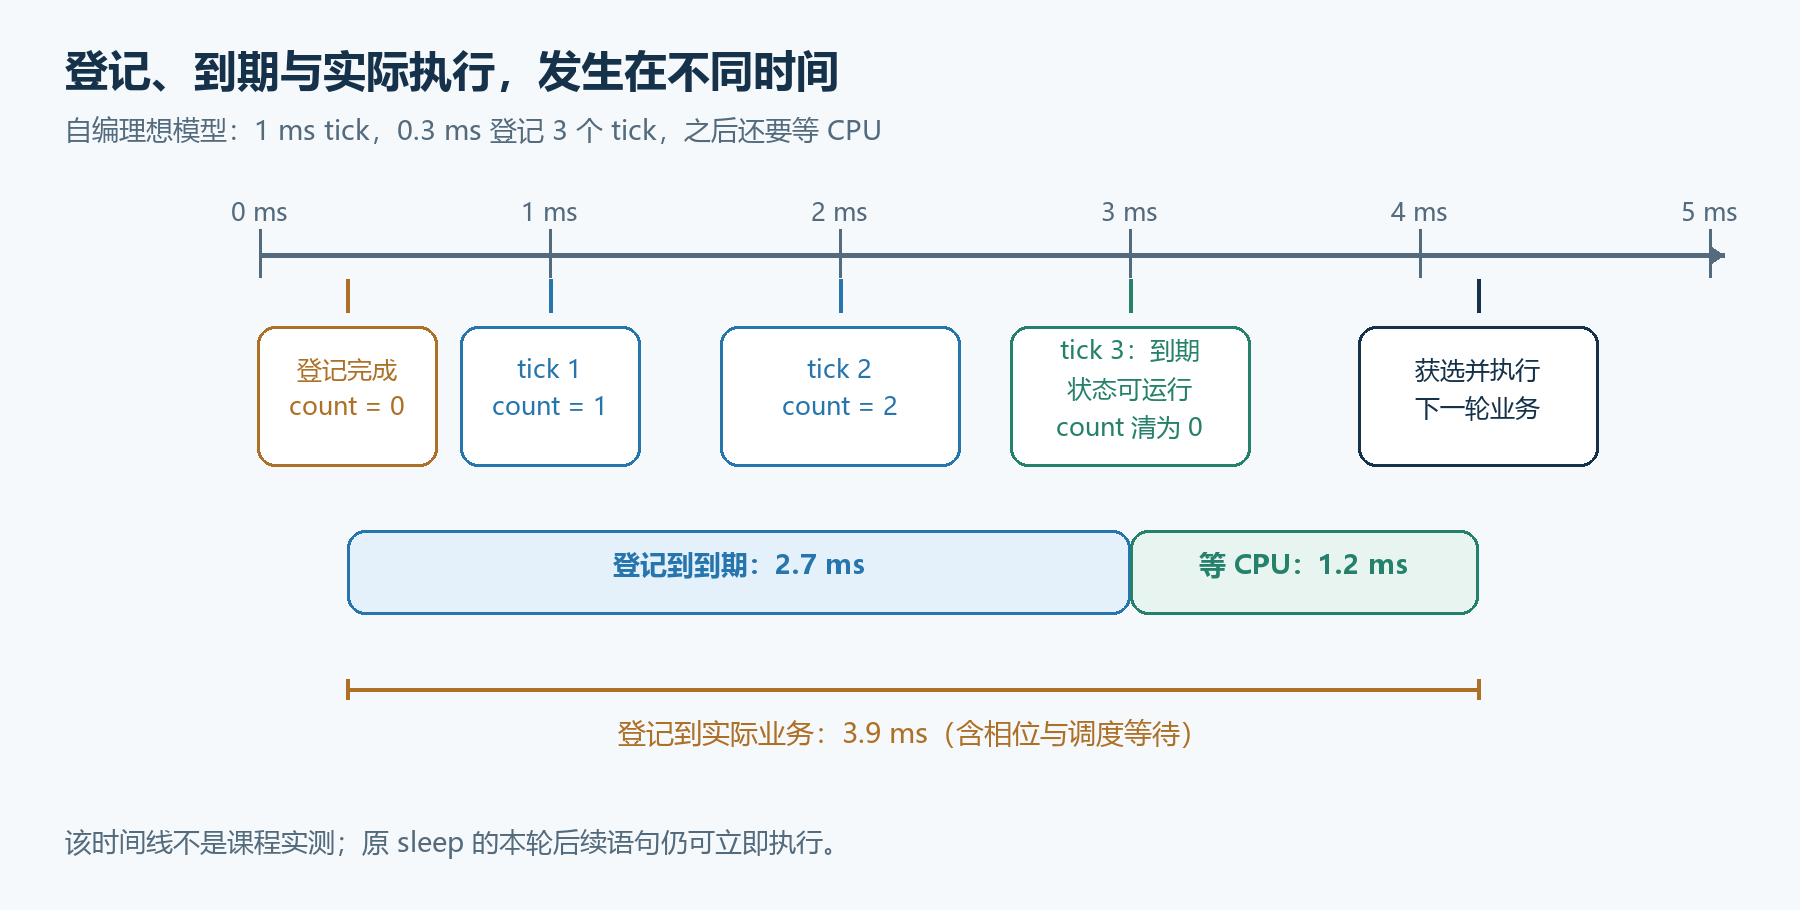

*自绘补充模型：T=1ms，0.3ms登记3个tick，3ms到期，示例4.2ms才得到CPU。不是课程实测波形。*

若业务要求“至少经过完整1000ms”，就不能不加说明地把“下1000个tick”视为严格下界；可依据契约加入边界处理，或用更合适的真实时刻判断。

到期后还可能等CPU，再执行驱动或GPIO操作：

```text
登记等待 → 计时到期 → 可运行 → 被调度 → 业务动作
```

不能从定时器周期直接推断唤醒任务的最大响应时间。协作任务若迟迟不让出，另一个已到期任务仍可能等很久。


## 20. 轮转如何面对挂起任务？

源码 `task_switch` 只增加编号并回绕，没有筛选 `TASK_SUSPENDED`。任务被恢复后自己检查，仍等待就立即调用切换函数。

| 情况 | 当前简化例子的行为 |
|---|---|
| A等待，B可运行 | A仍可能被轮转选中，然后检查并让出 |
| A、B都等待 | 两者可能持续执行检查与让出代码 |
| T0让A到期 | 仅状态改变，下一次得到CPU后才执行业务 |
| B长时间不主动让出 | 若没有正确启用的抢占路径，A到期也不能强制获得CPU |

**补充方向：**更完整的调度器从就绪任务中选择；无就绪业务任务时进入明确的空闲路径。阻塞等待的调用契约、定时唤醒与就绪队列一起设计，才能减少无用的轮流检查。

两个定时器不是实现操作系统的必需数量：也可以由统一tick计时，并按累计tick触发调度。无论来源怎样组织，选择、上下文、返回协议和共享数据仍是独立要求。


## 21. 用逐层验证检查计时和调度

以下为**补充验证路线，尚未在本环境执行**。

| 层次 | 观察什么 | 应确认什么 |
|---|---|---|
| 时钟 | 实际系统频率、1T/12T配置 | 周期计算有正确输入 |
| 计数器 | 模式、初值、启动顺序 | 首次与稳定重装周期符合预期 |
| ISR | 允许位、向量、入口标记 | 事件真的进入，服务没有长时间遗漏 |
| 等待数据 | status/count/duration | 完整登记、每tick变化、到期复位 |
| 任务业务 | 等待调用和输出边沿 | 清楚“登记后本轮仍执行”的契约 |
| 调度 | 就绪任务与任务运行标记 | 唤醒到执行的延迟可解释 |
| 上下文 | 寄存器、SP、帧与RETI | 抢占后继续状态正确 |

可先用单任务验证计时，再加入另一任务与等待，再在满足上下文协议后验证抢占。不要一次性启用所有来源，只凭LED能闪就判断全部正确。

关键边界用例包括：0、1、1000、65535 tick，非法编号、两个任务同时等待、不同登记相位、任务与ISR交错、较长临界区、首次计时与运行中重装。实际应用仍需按其接口契约选择测试，不必把补充列表当作当前已有测试报告。

ISR插桩脉冲间距表示服务事件间隔，不自动等于纯硬件溢出周期；若每次ISR只翻转一个标记位，同方向边沿的完整周期是ISR间隔的两倍，第04篇的测量区分仍适用。


## 22. 一页复习与自测

| 知识点 | 本篇结论 |
|---|---|
| sleep | 当前实现登记参数后返回，不在函数内阻塞 |
| 任务状态 | RUNNING在本例更接近允许业务，不区分就绪与执行 |
| T0 ISR | 挂起才加计数，所有项都做阈值比较；到期仅改状态 |
| STC8H模式0 | 16位自动重装，与经典8051模式0不同 |
| 运行中写TH/TL | 更新隐藏重装值，不能当作当前计数立即被设置 |
| 计时单位 | duration是tick阈值，tick=1ms时才对应毫秒 |
| 时钟证据 | 源码注释24MHz、工程描述35MHz，实际时钟需确认 |
| T1启用 | 原代码没有开启ET1；TR1与ISR定义不替代允许位 |
| tick与时间片 | 一个是计时基准，一个是调度策略中的运行预算 |
| 完整切换 | 定期ISR仍需保护上下文、统一恢复帧与RETI协议 |
| 数据同步 | volatile、原子更新和临界区各有不同职责 |
| 到期与执行 | tick相位、ISR响应和调度等待影响实际业务时刻 |

### 自测题

1. 调用当前 `sleep(0,1000)` 后，是否在函数内停住一秒？
2. 为什么两个任务都能标为 `TASK_RUNNING`？
3. T0 ISR第二个比较是否只在挂起时执行？
4. `delay_duration=3`时，第3个正常服务tick之后，计数保留3还是清0？
5. STC8H的T0/T1模式0是多少位、是否自动重装？
6. TR0=1时写TH0/TL0，是否立即改写当前计数值？
7. 24MHz、1T、重装0xA240时，稳定周期是多少？
8. 同一重装值、实际35MHz时，1000个稳定tick约经过多久？
9. 源码T1初始化为什么不能证明100μs抢占已工作？
10. 只补 `ET1=1` 是否解决了完整上下文切换？
11. sleep先写挂起状态再写新阈值，可能发生什么交错？
12. `volatile`是否保证16位字段或三个字段整体更新原子化？
13. 1ms tick、从0计数1000次，是否严格保证至少1000ms？
14. 等待到期的任务是否一定立即获得CPU？

### 参考答案

1. 不会。它登记状态与参数后返回，任务后来显式让出并检查状态。
2. 该字段表示允许继续业务，没有严格区分就绪与当前执行。
3. 不是，它位于挂起条件外，对每项任务执行。
4. 达到阈值后改可运行，并把计数清0。
5. 16位自动重装载。
6. 不会按这种方式直接改当前计数，写入隐藏重装值。
7. `(65536-0xA240)/24000000=1ms`。
8. 约0.685714秒；这是35MHz假设计算，不是实际时钟测量。
9. 没有开启ET1，也没有提供已验证的抢占上下文与返回协议。
10. 没有，还需完整状态保护、帧格式、RETI路径和调度同步。
11. ISR可能看到旧阈值0而提前改回可运行，新等待没有正确建立。
12. 都不保证，仍需按访问与同步需求设计。
13. 不保证严格下界；理想计数模型约999—1000ms，与请求相位有关。
14. 不一定，可能仍需等当前任务让出、调度或中断处理结束。

### 自编计算练习

实际SYSclk为24MHz，1T模式，希望稳定T0周期2ms：需要多少次计数，16位重装值是多少？若此时仍原样传 `sleep(0,1000)`，名义等待变为多久？

**答案：**计数 `24000000×0.002=48000`；重装 `65536-48000=17536=0x4480`，TH=0x44、TL=0x80。1000个tick名义为2秒，仍受登记相位、ISR服务与调度延迟影响。


## 23. 五篇知识链与资料来源

| 编号 | 笔记 | 对应视频 | 串起的关键问题 |
|---|---|---|---|
| 01 | [操作系统基础、多任务与资源调度](01-操作系统基础、多任务与资源调度.ipynb) | 01—08 | 为什么需要任务、调度和上下文 |
| 02 | [STC内存、任务堆栈与任务切换原理](02-STC内存、任务堆栈与任务切换原理.ipynb) | 09—13 | 换SP后怎样由RET改变继续位置 |
| 03 | [任务调度器与上下文保护](03-任务调度器与上下文保护.ipynb) | 14—15 | 选谁运行，以及怎样恢复它的状态 |
| 04 | [多任务外设访问与延时问题](04-多任务外设访问与延时问题.ipynb) | 16—17 | 外设怎样共享，CPU执行量与真实时间怎样区分 |
| 05 | sleep实现与定时时间片轮转 | 18—19 | 用硬件计时登记、到期、唤醒，并理解定期调度 |

完整知识链可以写成：

```text
任务与状态 → 任务栈和返回地址 → 选择与上下文恢复
→ 共享外设和时间测量 → 计时等待、唤醒与定期调度
```

课程来源：[《自己动手写嵌入式操作系统》网盘](https://pan.baidu.com/s/1BaPETt4F3Xnew179lHT4DA?pwd=9988)，提取码 `9988`；配套代码为 `代码/os_demo.zip`。

| 证据 | 本篇使用范围 |
|---|---|
| main.c | Task、sleep、Timer0/1、任务循环与初始化顺序 |
| main.lst、project.m51 | 编译配置、函数位置、内部数据布局 |
| project.hex | sleep多字节写入、ISR和定时器初始化的实际指令 |
| project.uvproj | 目标型号及CLOCK(35000000)工程描述 |
| [STC8H技术参考手册](https://stcmicro.com/datasheet/STC8H-cn.pdf)第14章 | 模式0、TH/TL重装语义、TF标志与周期公式；PDF476—478、480—481、483—484页，以及492、504页范例 |
| 本篇图示、交错表与计算练习 | 自绘/自编补充说明，没有作为视频逐字内容或硬件记录 |

五篇到这里覆盖已规划的19个视频主题。配套示例适合拆解内核机制；将它用于新的硬件项目时，仍需要按实际型号、工具链和业务要求完成计时、同步、栈及上下文的实现与验证。
